# RADOLAN adjustment example with OpenMRG CML data 

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import poligrain as plg
import xarray as xr

import mergeplg as mrg

## Load and prepare OpenMRG data

In [2]:
ds_rad, ds_cmls, ds_gauges, ds_gauges_smhi = mrg.io.load_and_transform_openmrg_data()

# UTM32N: https://epsg.io/32632
ref_str = "EPSG:32632"

# Fix error where lat/lon was set to variable
ds_rad = ds_rad.set_coords(["longitudes", "latitudes"])
ds_rad = ds_rad.rename({"rainfall_amount": "rainfall_radar"})

# Fix naming errors
ds_rad = ds_rad.rename({"longitudes": "lon", "latitudes": "lat"})

# Reproject radar and CML coordinates to UTM32N
# For CML
(
    ds_cmls.coords["site_0_x"],
    ds_cmls.coords["site_0_y"],
) = plg.spatial.project_point_coordinates(
    ds_cmls.site_0_lon, ds_cmls.site_0_lat, ref_str
)
(
    ds_cmls.coords["site_1_x"],
    ds_cmls.coords["site_1_y"],
) = plg.spatial.project_point_coordinates(
    ds_cmls.site_1_lon, ds_cmls.site_1_lat, ref_str
)

# Midpoint
ds_cmls.coords["x"] = (ds_cmls.site_0_x + ds_cmls.site_1_x) / 2
ds_cmls.coords["y"] = (ds_cmls.site_0_y + ds_cmls.site_1_y) / 2

# Projected radar coords
ds_rad.coords["x_grid"], ds_rad.coords["y_grid"] = (
    plg.spatial.project_point_coordinates(ds_rad.lon, ds_rad.lat, ref_str)
)

## Set up RADOLAN merger object and loop over time steps to apply adjustment

In [3]:
merger = mrg.merge.MergeRADOLAN(
    ds_rad=ds_rad.rainfall_radar,
    ds_cmls=ds_cmls,
    max_distance=30e3,
    grid_location_radar="lower_left",
)

rainfall = []
for time in ds_cmls.time.data:
    rainfall.append(
        merger(
            da_rad=ds_rad.sel(time=time).rainfall_radar,
            da_cmls=ds_cmls.R.sel(time=time),
            start_index_in_relevant_stations="random",
        )
    )
ds_radolan = xr.concat(rainfall, dim="time")

The adjusted product is called `RW`. Note that for DWD's radar-adjustment product, the `RW` product is an hourly radar-gauge adjustment. Here, we apply the same adjustment steps to the 5min data. Radar-adjustment at this temporal resolution is challenging due to spatio-temporal mismatch of radar observations and ground observations from gauge and/or CML.

All intermediate products of the RADOLAN adjustment method are stored in the returned xr.Dataset

In [4]:
ds_radolan.data_vars

Data variables:
    RH                           (time, y, x) float64 440kB 0.01078 ... 0.05403
    RG                           (time, y, x) float64 440kB 0.01078 ... 0.05403
    RB                           (time, y, x) float64 440kB 0.01078 ... 0.05403
    dbr_interim                  (time, y, x) float64 440kB 0.0 0.0 ... 0.0 0.0
    fbr_interim                  (time, y, x) float64 440kB 1.0 1.0 ... 1.0 1.0
    addiff_interim               (time, y, x) float64 440kB 0.01078 ... 0.05403
    mulfak_interim               (time, y, x) float64 440kB 0.01078 ... 0.05403
    weight_addiff_interim_audit  (time, y, x) float64 440kB 0.5 0.5 ... 0.5 0.5
    weight_mulfak_interim_audit  (time, y, x) float64 440kB 0.5 0.5 ... 0.5 0.5
    dbr_relevant                 (time, y, x) float64 440kB 0.0 0.0 ... 0.0 0.0
    fbr_relevant                 (time, y, x) float64 440kB 1.0 1.0 ... 1.0 1.0
    addiff_relevant              (time, y, x) float64 440kB 0.01078 ... 0.05403
    mulfak_relevant     

## Compare unadjusted and adjusted radar rainfall fields

### Look at rainfall sum of example dataset

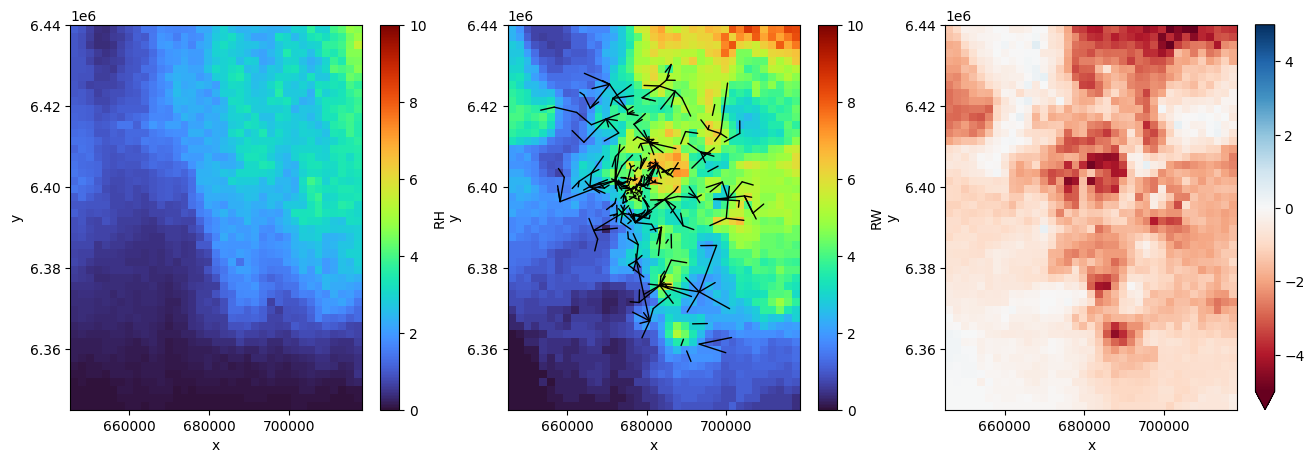

In [5]:
vmin, vmax = 0, 10
cmap = "turbo"
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
ds_radolan.sum(dim="time").RH.plot(ax=axs[0], vmin=vmin, vmax=vmax, cmap=cmap)
ds_radolan.sum(dim="time").RW.plot(ax=axs[1], vmin=vmin, vmax=vmax, cmap=cmap)
(ds_radolan.sum(dim="time").RH - ds_radolan.sum(dim="time").RW).plot(
    ax=axs[2],
    vmin=-5,
    vmax=5,
    cmap="RdBu",
)

plg.plot_map.scatter_lines(
    x0=ds_cmls.site_0_x,
    x1=ds_cmls.site_1_x,
    y0=ds_cmls.site_0_y,
    y1=ds_cmls.site_1_y,
    ax=axs[1],
    s=1,
    c="k",
)

### Look at individual time stamps

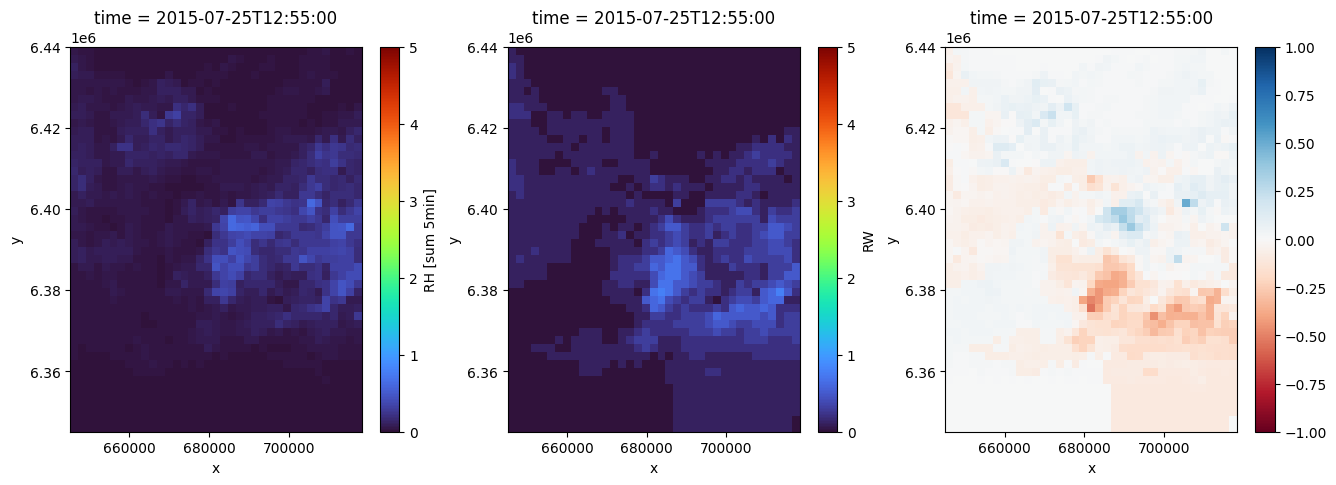

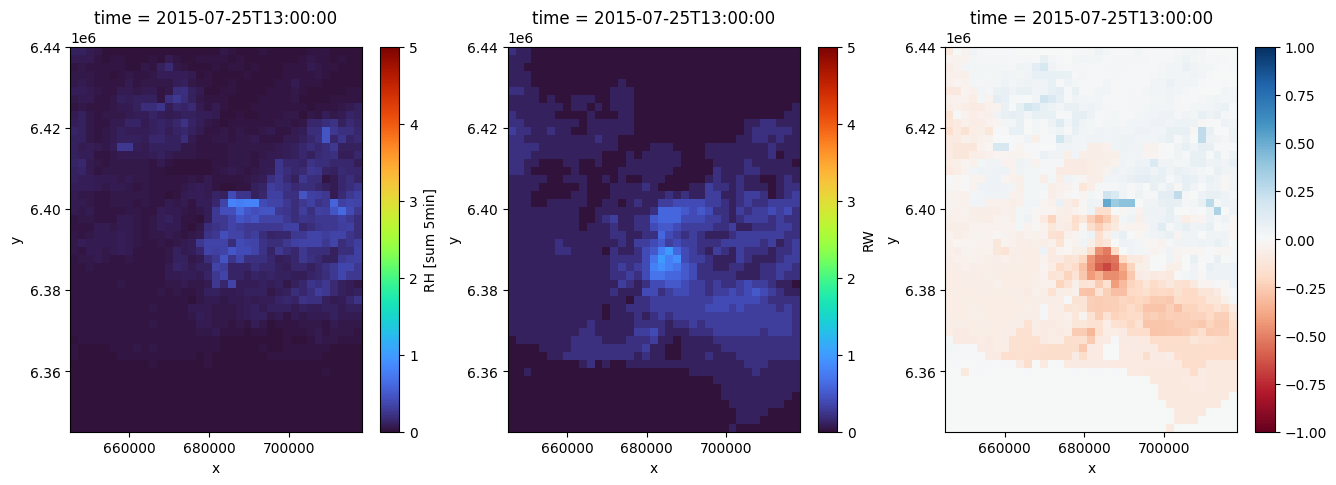

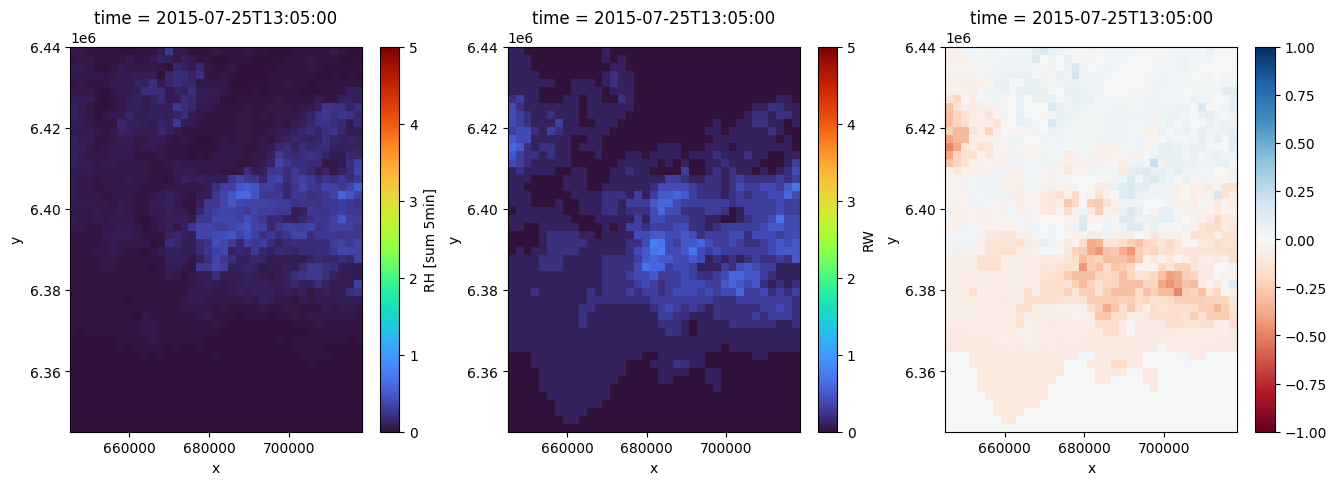

In [6]:
for t in ds_radolan.time.data[5:8]:
    vmin, vmax = 0, 5
    cmap = "turbo"
    fig, axs = plt.subplots(1, 3, figsize=(16, 5))
    ds_radolan.sel(time=t).RH.plot(ax=axs[0], vmin=vmin, vmax=vmax, cmap=cmap)
    ds_radolan.sel(time=t).RW.plot(ax=axs[1], vmin=vmin, vmax=vmax, cmap=cmap)
    (ds_radolan.sel(time=t).RH - ds_radolan.sel(time=t).RW).plot(
        ax=axs[2],
        vmin=-1,
        vmax=1,
        cmap="RdBu",
    )

## Validate unadjusted and adjusted radar rainfall fields at gauge locations

In [7]:
grid_at_points = plg.spatial.GridAtPoints(
    da_gridded_data=ds_rad.rainfall_radar,
    da_point_data=ds_gauges.rainfall_amount.rename({"station_id": "id"}),
    nnear=1,
)

ds_gauges.coords["id"] = ds_gauges.station_id

In [8]:
radar_at_gauges = grid_at_points(
    da_gridded_data=ds_rad.rainfall_radar,
    da_point_data=ds_gauges.rainfall_amount,
)

RW_at_gauges = grid_at_points(
    da_gridded_data=ds_radolan.RW_not_rounded,
    da_point_data=ds_gauges.rainfall_amount,
)

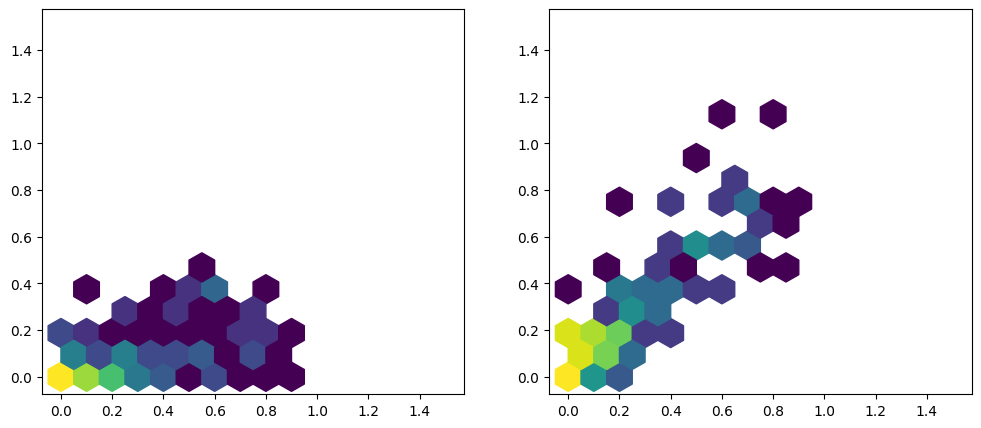

In [9]:
extent = [0, 1.5, 0, 1.5]
gridsize = 15

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

axs[0].hexbin(
    ds_gauges.rainfall_amount,
    radar_at_gauges,
    mincnt=1,
    extent=extent,
    gridsize=gridsize,
    bins="log",
)

axs[1].hexbin(
    ds_gauges.rainfall_amount,
    RW_at_gauges,
    mincnt=1,
    extent=extent,
    gridsize=gridsize,
    bins="log",
);

In [10]:
R_gauge = ds_gauges.rainfall_amount.data.flatten()
R_unadjusted = radar_at_gauges.data.flatten()
R_adjusted = RW_at_gauges.data.flatten()

corr_unadjusted = np.corrcoef(R_gauge, R_unadjusted)[0, 1]
corr_adjusted = np.corrcoef(R_gauge, R_adjusted)[0, 1]

rmse_unadjusted = np.sqrt(np.mean((R_gauge - R_unadjusted) ** 2))
rmse_adjusted = np.sqrt(np.mean((R_gauge - R_adjusted) ** 2))

print("  unadjusted adjusted")
print(f"PCC:  {corr_unadjusted:0.2f}     {corr_adjusted:0.2f}")
print(f"RMSE: {rmse_unadjusted:0.2f}     {rmse_adjusted:0.2f}")

  unadjusted adjusted
PCC:  0.63     0.86
RMSE: 0.20     0.12
